# EDA — FakeTrue.Br

Explora o `FakeTrue.Br`: 1.791 pares de textos, cada um com um boato coletado do **Boatos.org** (`fake`) e um texto de veículo jornalístico sobre o mesmo assunto (`true`), um CSV único com as colunas `title_fake`, `fake`, `link_f`, `true` e `link_t`.

Diferente do Fake.br-Corpus, este dataset não tem metadados (datas, categorias, métricas de estilo) nem versão normalizada por tamanho — essas análises são reconstruídas aqui a partir do próprio texto e das URLs.

Dataset esperado em `../data/raw/FakeTrue.Br/` (link simbólico para o clone local). Definições das métricas: [glossário](../references/glossario-metricas.md).

In [20]:
import re
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

CSV = Path("../data/raw/FakeTrue.Br/FakeTrueBr_corpus.csv")
SEED = 42

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)

## 1. Carregamento dos dados

O CSV tem um par por linha. Para analisar as classes lado a lado, ele é convertido para uma linha por texto. Duas chaves de agrupamento são guardadas:

- `par`: número da linha original (o par boato/texto verdadeiro);
- `grupo`: o link do texto verdadeiro. Como o mesmo texto verdadeiro aparece em vários pares (ver seção 2), é esse o agrupamento que evita vazamento na validação cruzada.

In [21]:
bruto = pd.read_csv(CSV)

fake = pd.DataFrame({
    "par": bruto.index, "classe": "fake", "titulo": bruto["title_fake"].str.strip(),
    "texto": bruto["fake"].str.strip(), "link": bruto["link_f"], "grupo": bruto["link_t"],
})
true = pd.DataFrame({
    "par": bruto.index, "classe": "true", "titulo": pd.NA,
    "texto": bruto["true"].str.strip(), "link": bruto["link_t"], "grupo": bruto["link_t"],
})
df = pd.concat([fake, true], ignore_index=True)
df["dominio"] = df["link"].str.extract(r"https?://(?:www\d?\.)?([^/]+)")[0]
df["n_palavras_texto"] = df["texto"].str.split().str.len()
df["ano_url"] = df["link"].str.extract(r"/(20\d{2})/")[0].astype("Int64")
print("Pares no CSV:", len(bruto), "| Textos:", len(df))

Pares no CSV: 1791 | Textos: 3582


## 2. Estrutura e qualidade

In [22]:
print("Nulos no CSV original:\n", bruto.isnull().sum())
print("\nTextos vazios:", (df["n_palavras_texto"] == 0).sum())

print("\nTextos duplicados dentro de cada classe:")
print(df.groupby("classe")["texto"].apply(lambda s: s.duplicated().sum()))

reuso = bruto["link_t"].value_counts()
print(f"\nTextos verdadeiros distintos: {reuso.size} para {len(bruto)} pares")
print(f"Textos verdadeiros usados em mais de um par: {(reuso > 1).sum()} (máximo: {reuso.max()} pares)")
print(f"Pares afetados: {reuso[reuso > 1].sum()} de {len(bruto)}")

Nulos no CSV original:
 title_fake    0
fake          0
link_f        0
true          0
link_t        0
dtype: int64

Textos vazios: 0

Textos duplicados dentro de cada classe:
classe
fake     12
true    388
Name: texto, dtype: int64

Textos verdadeiros distintos: 1344 para 1791 pares
Textos verdadeiros usados em mais de um par: 277 (máximo: 12 pares)
Pares afetados: 724 de 1791


**Como ler:** o README do dataset informa 3.582 artigos = 1.791 pares × 2, o que bate com o CSV. Mas o número de textos verdadeiros **distintos** é menor: o mesmo texto verdadeiro foi pareado com vários boatos. Na validação cruzada, isso exige agrupar pelo texto verdadeiro — senão o mesmo texto cai no treino e no teste ([vazamento](../references/glossario-metricas.md)).

### 2.1 Sinais de pré-processamento

Os textos já chegam transformados. Vale medir o quê, porque algumas transformações apagam sinais de estilo e outras foram aplicadas de forma diferente em cada classe — o que vira atalho.

In [23]:
sinais = pd.DataFrame({
    "tem_maiuscula": df["texto"].str.contains(r"[A-ZÁÉÍÓÚÂÊÔÃÕÇ]"),
    "tem_digito": df["texto"].str.contains(r"\d"),
    "tem_hifen": df["texto"].str.contains(r"\w-\w"),
    "tem_acento": df["texto"].str.contains(r"[áéíóúâêôãõç]"),
    "tem_ano_sem_zero": df["texto"].str.contains(r"\b2[12]\d\b"),
    "classe": df["classe"],
})
print("Proporção de textos com cada característica:")
print(sinais.groupby("classe").mean().T.round(3))

anos = pd.Series(re.findall(r"\b2\d{2,3}\b", " ".join(df["texto"])))
print("\nNúmeros com cara de ano mais frequentes:\n", anos.value_counts().head(8))

Proporção de textos com cada característica:
classe             fake   true
tem_maiuscula     0.000  0.140
tem_digito        0.729  0.956
tem_hifen         0.399  0.730
tem_acento        0.671  1.000
tem_ano_sem_zero  0.078  0.406

Números com cara de ano mais frequentes:
 218     336
219     300
222     265
221     229
215     155
217     151
216     126
2020    116
Name: count, dtype: int64


**Como ler:** `tem_maiuscula` perto de 0 = texto convertido para minúsculas. Se a proporção difere entre as classes, a simples presença de uma letra maiúscula denuncia a classe (atalho criado pelo pré-processamento, não pelo conteúdo). `tem_hifen` perto de 0 indica hífens removidos ("ex-presidente" → "expresidente"). Números como `218`, `222` são anos que perderam o zero ("2018", "2022"). `tem_acento` menor nas fakes = parte delas perdeu a acentuação ("não" → "nao"): palavras sem acento passam a denunciar a classe, outro atalho de pré-processamento.

## 3. Balanceamento de classes

In [24]:
print(df["classe"].value_counts())

classe
fake    1791
true    1791
Name: count, dtype: int64


**Como ler:** 1.791 × 1.791 = balanceado por construção (um boato e um texto verdadeiro por linha).

## 4. Leitura de amostras

Antes das estatísticas: ler textos reais de cada classe.

In [25]:
for classe in ["fake", "true"]:
    print(f"{'=' * 30} {classe.upper()} {'=' * 30}")
    for _, linha in df[df["classe"] == classe].sample(4, random_state=SEED).iterrows():
        print(f"\n[par {linha['par']} | {linha['dominio']} | {linha['n_palavras_texto']} palavras]")
        print(linha["texto"][:450])
    print()

============================== FAKE ==============================

[par 1310 | boatos.org | 130 palavras]
show da virada tem fracasso de venda de ingressos e sera cancelado [] a edicao 2019 do programa de fim de ano show da virada, que era para ocorrer no proximo dia 18 de dezembro, foi cancelado por falta de publico.a organizacao do evento esperava 15 mil pessoas, mas a apresentacao atraiu apenas 170 fas, que terao o dinheiro devolvido. as informacoes do portal a fofoca expectativa: a edicao 2019 contava com os shows de luan santana, pablo vittar, d

[par 843 | boatos.org | 204 palavras]
crivella apresenta propostas para reabertura do comércio; plano prevê retorno de aulas em 1° de junho o prefeito do rio, marcelo crivella, apresenta neste fim de semana à comunidade científica propostas para a reabertura da atividade econômica na cidade. …, os principais pontos previstos no projeto são: a partir do dia 1º de junho: reabertura das escolas para o ensino médio (com uso obrigatório de má

### 4.1 Natureza do texto verdadeiro

A leitura das amostras sugere que o texto verdadeiro, em boa parte dos pares, é uma **checagem** do próprio boato (cita a alegação e a desmente), e não uma notícia comum. A célula abaixo mede isso com termos típicos de checagem.

In [26]:
TERMOS_CHECAGEM = ["circula", "fato ou fake", "é fake", "checagem", "falso", "montagem", "é . ,"]
presenca = pd.DataFrame({
    termo: df.groupby("classe")["texto"].apply(lambda s, t=termo: s.str.contains(re.escape(t)).mean())
    for termo in TERMOS_CHECAGEM
}).T
print("Proporção de textos que contêm cada termo:")
print(presenca.round(3))
print("\nTextos verdadeiros vindos de URLs /fato-ou-fake/:",
      round(df.loc[df["classe"] == "true", "link"].str.contains("fato-ou-fake").mean(), 3))

Proporção de textos que contêm cada termo:
classe         fake   true
circula       0.027  0.638
fato ou fake  0.001  0.146
é fake        0.003  0.031
checagem      0.000  0.077
falso         0.015  0.164
montagem      0.001  0.052
é . ,         0.000  0.529

Textos verdadeiros vindos de URLs /fato-ou-fake/: 0.582


**Como ler:** termos como "circula" ("circula nas redes"), "fato ou fake" e o resíduo `é . ,` (o selo "É #FAKE" com a palavra removida no pré-processamento) aparecem quase só no lado `true`. Isso confirma que o par é, na maioria dos casos, **boato × checagem do boato**, e não notícia falsa × notícia verdadeira.

### 4.2 Frases repetidas (boilerplate)

Frases que se repetem em muitos documentos costumam ser assinaturas do site ou chamadas coletadas junto com o texto. Como o mesmo rodapé aparece com pequenas variações (outro telefone, dois-pontos a mais, com ou sem acento), as frases são comparadas depois de **canonicalizadas**: sem acentos, números, pontuação e espaços extras. Variações que só diferem nisso contam como um mesmo grupo.

In [27]:
def frases(texto: str) -> list:
    partes = re.split(r"[.!?]\s+|\s+,\s+,\s*|\n+", texto.lower())
    return [p.strip(" ,") for p in partes if len(p.strip(" ,")) > 20]


def canonica(frase: str) -> str:
    sem_acento = unicodedata.normalize("NFKD", frase).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", re.sub(r"[\d\W_]+", " ", sem_acento)).strip()


LIMIAR_BOILERPLATE = 20
docs_por_grupo = Counter()
classes_por_grupo = defaultdict(Counter)
variantes = defaultdict(Counter)
for texto, classe in zip(df["texto"], df["classe"]):
    frases_do_texto = set(frases(texto))
    for grupo in {canonica(f) for f in frases_do_texto}:
        docs_por_grupo[grupo] += 1
        classes_por_grupo[grupo][classe] += 1
    for frase in frases_do_texto:
        variantes[canonica(frase)][frase] += 1

grupos_boilerplate = [g for g, n in docs_por_grupo.items() if n >= LIMIAR_BOILERPLATE]
BOILERPLATE = sorted({v for g in grupos_boilerplate for v in variantes[g]}, key=len, reverse=True)
print(f"Grupos em {LIMIAR_BOILERPLATE}+ documentos: {len(grupos_boilerplate)} "
      f"(somando {len(BOILERPLATE)} variações de escrita)\n")
for grupo, n in docs_por_grupo.most_common(15):
    if n < LIMIAR_BOILERPLATE:
        break
    exemplo = variantes[grupo].most_common(1)[0][0]
    print(f"{n:>5} docs {dict(classes_por_grupo[grupo])} | {len(variantes[grupo])} variações | ex.: {exemplo[:90]}")

Grupos em 20+ documentos: 10 (somando 26 variações de escrita)

  161 docs {'true': 161} | 4 variações | ex.: vídeo: veja como identificar uma mensagem falsa
   92 docs {'fake': 92} | 7 variações | ex.: se voce quiser sugerir um tema ao boatos.org, entre em contato com a gente pelo site, face
   56 docs {'true': 56} | 2 variações | ex.: vídeo veja como identificar se uma mensagem é falsa
   56 docs {'true': 56} | 1 variações | ex.: enviar siga uol notícias enviar
   27 docs {'fake': 27} | 1 variações | ex.: se voce quiser sugerir um tema ao boatos.org, entre em contato com a gente pelo site, face
   25 docs {'true': 25} | 4 variações | ex.: é ou não é?’, seção de fact-checking (checagem de fatos) do g1, tem como objetivo conferir
   22 docs {'fake': 22} | 1 variações | ex.: se voce quiser sugerir um tema ao boatos.org, entre em contato com a gente pelo site, face
   22 docs {'true': 22} | 2 variações | ex.: sugestões podem ser enviadas pelo vc no g1, pelo fale conosco ou pelo whatsapp/

**Como ler:** `nº de docs {classe: quantos} | nº de variações | exemplo`. O número de docs já soma todas as variações do grupo. Grupo concentrado numa só classe = assinatura de veículo, não conteúdo ([boilerplate](../references/glossario-metricas.md)). Variações que mudam palavras ("identificar **se** uma mensagem **é** falsa") continuam em grupos separados; por isso o mascaramento também usa padrões explícitos (seção 10.2.1). Parte das contagens do lado `true` é inflada pelos textos verdadeiros repetidos (seção 2).

## 5. Distribuição de comprimento de texto

         count   mean    std   min    25%    50%    75%     max
classe                                                         
fake    1791.0  143.9  116.3  17.0   69.0  109.0  179.0  1241.0
true    1791.0  507.1  461.7  47.0  253.5  377.0  610.0  5466.0

 mediana_fake    109.0000
mediana_true    377.0000
cliffs_delta     -0.8063
p_valor           0.0000
dtype: float64


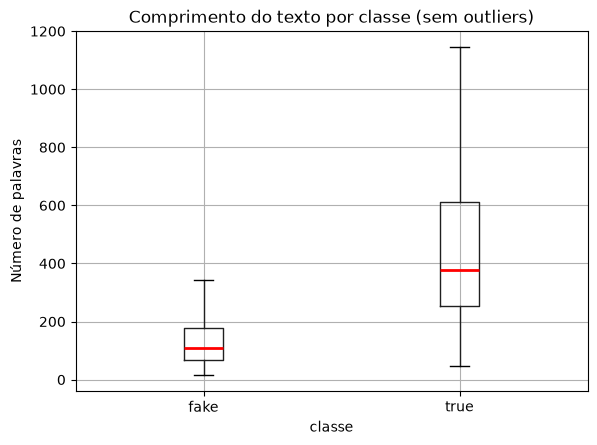

In [28]:
def cliffs_delta(a, b) -> float:
    u, _ = mannwhitneyu(a, b, alternative="two-sided")
    return 2 * u / (len(a) * len(b)) - 1


def comparar(coluna: str, dados: pd.DataFrame = df) -> dict:
    fake = dados.loc[dados["classe"] == "fake", coluna].dropna()
    true = dados.loc[dados["classe"] == "true", coluna].dropna()
    _, p = mannwhitneyu(fake, true, alternative="two-sided")
    return {"mediana_fake": fake.median(), "mediana_true": true.median(),
            "cliffs_delta": cliffs_delta(fake, true), "p_valor": p}


print(df.groupby("classe")["n_palavras_texto"].describe().round(1))
print("\n", pd.Series(comparar("n_palavras_texto")).round(4))

ax = df.boxplot(column="n_palavras_texto", by="classe", showfliers=False,
                medianprops={"color": "red", "linewidth": 2})
ax.set_title("Comprimento do texto por classe (sem outliers)")
plt.suptitle("")
ax.set_ylabel("Número de palavras")
plt.show()

**Como ler:** compare as **medianas** (`50%`) e o **δ de Cliff**: negativo = true maior; |δ| ≥ 0,474 = efeito grande. Linha vermelha no boxplot = mediana. Definições no [glossário](../references/glossario-metricas.md).

## 6. Vocabulário discriminativo (chi²)

O dataset não tem versão normalizada por tamanho, então ela é reconstruída aqui com a mesma regra do Fake.br-Corpus: em cada par, os dois textos são cortados para o tamanho do mais curto (mantendo o início).

In [29]:
try:
    import nltk

    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords

    STOPWORDS_PT = stopwords.words("portuguese")
except Exception:
    STOPWORDS_PT = [
        "a", "o", "e", "é", "de", "da", "do", "das", "dos", "em", "um", "uma", "para",
        "por", "com", "que", "se", "não", "mais", "como", "mas", "ou", "no", "na", "nos",
        "nas", "ao", "aos", "à", "às", "pelo", "pela", "seu", "sua", "ele", "ela", "foi",
    ]

palavras_fake = bruto["fake"].str.split()
palavras_true = bruto["true"].str.split()
tamanho_par = [min(len(a), len(b)) for a, b in zip(palavras_fake, palavras_true)]
df_trunc = pd.concat([
    pd.DataFrame({"par": bruto.index, "classe": "fake", "grupo": bruto["link_t"],
                  "texto": [" ".join(p[:n]) for p, n in zip(palavras_fake, tamanho_par)]}),
    pd.DataFrame({"par": bruto.index, "classe": "true", "grupo": bruto["link_t"],
                  "texto": [" ".join(p[:n]) for p, n in zip(palavras_true, tamanho_par)]}),
], ignore_index=True)


def termos_discriminativos(textos: pd.Series, classes: pd.Series, top_n: int = 20) -> tuple:
    vetorizador = CountVectorizer(binary=True, ngram_range=(1, 2), min_df=5, stop_words=STOPWORDS_PT)
    X = vetorizador.fit_transform(textos)
    e_fake = (classes == "fake").to_numpy()
    scores, _ = chi2(X, e_fake)
    tabela = pd.DataFrame({
        "chi2": scores,
        "prop_fake": np.asarray(X[e_fake].mean(axis=0)).ravel(),
        "prop_true": np.asarray(X[~e_fake].mean(axis=0)).ravel(),
    }, index=vetorizador.get_feature_names_out())
    top_fake = tabela[tabela.prop_fake > tabela.prop_true].nlargest(top_n, "chi2")
    top_true = tabela[tabela.prop_true > tabela.prop_fake].nlargest(top_n, "chi2")
    return top_fake.round(3), top_true.round(3)


top_fake, top_true = termos_discriminativos(df_trunc["texto"], df_trunc["classe"])
print("Termos mais associados a FAKE:\n", top_fake)
print("\nTermos mais associados a TRUE:\n", top_true)

/home/feliperodr/ResIA/Challenge1/experimentos/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/feliperodr/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


Termos mais associados a FAKE:
                       chi2  prop_fake  prop_true
nao                359.171      0.207      0.002
voce               302.201      0.175      0.002
sugestao           209.000      0.117      0.000
artigo sugestao    208.000      0.116      0.000
voce quiser        206.000      0.115      0.000
org contato        205.000      0.114      0.000
org                204.075      0.117      0.001
quiser sugerir     204.000      0.114      0.000
sugerir tema       201.000      0.112      0.000
quiser             199.681      0.127      0.006
boatos org         197.078      0.113      0.001
tema boatos        195.000      0.109      0.000
contato gente      193.000      0.108      0.000
sugerir            191.670      0.117      0.003
site facebook      189.000      0.106      0.000
gente site         186.021      0.106      0.001
ja                 179.022      0.102      0.001
61                 169.529      0.103      0.003
telefone 61        166.000      0.093

**Como ler:** `chi2` = força da associação (sem lado); o lado é a maior entre `prop_fake` e `prop_true`. Termos de checagem do lado `true` ("circula", "redes sociais", "falso") indicam que o modelo pode aprender "isto é um texto de checagem" em vez de "isto é verdadeiro". Ver [glossário](../references/glossario-metricas.md).

## 7. Estilo de escrita

Sem metadados, as métricas são calculadas a partir do texto. O pré-processamento limita o que dá para medir: maiúsculas (texto em minúsculas) e hífens foram removidos. Ficam as métricas que sobrevivem a isso, sempre como taxa ou razão, para não depender do tamanho do texto. O TTR é calculado nos textos truncados (seção 6).

                       mediana_fake  mediana_true  cliffs_delta  p_valor
exclamacoes_por_100          0.0000        0.0000        0.4012   0.0000
comp_medio_sentenca         14.6429       18.9412       -0.3965   0.0000
interrogacoes_por_100        0.0000        0.0000        0.1414   0.0000
comp_medio_palavra           4.7500        4.8067       -0.1041   0.0000
ttr_truncado                 0.6860        0.7015       -0.0731   0.0002


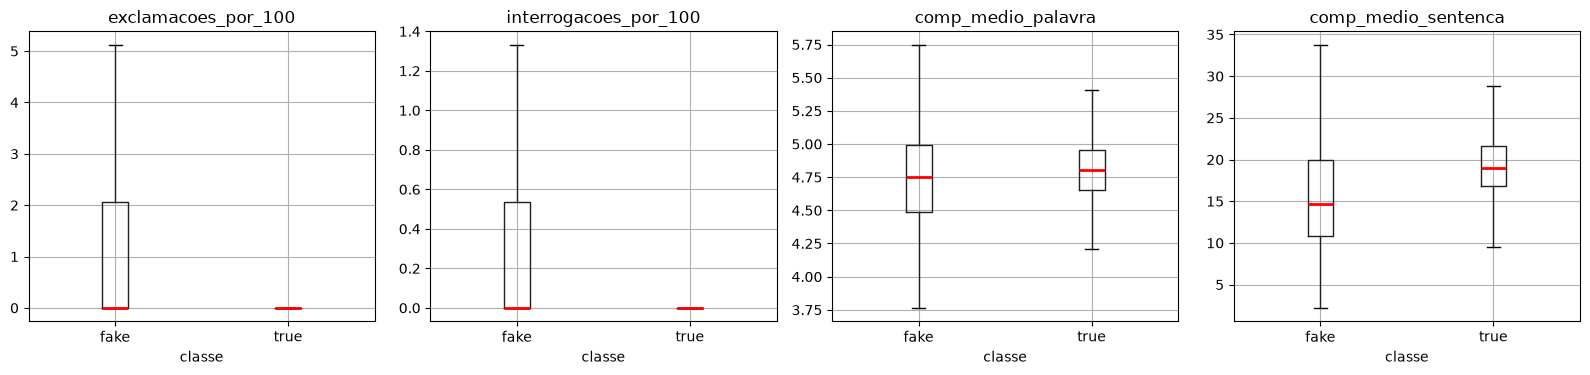

In [30]:
def comp_medio_palavra(texto: str) -> float:
    tokens = re.findall(r"\w+", texto)
    return np.mean([len(t) for t in tokens]) if tokens else np.nan


def comp_medio_sentenca(texto: str) -> float:
    sentencas = [s for s in re.split(r"[.!?]+", texto) if s.strip()]
    return len(texto.split()) / len(sentencas) if sentencas else np.nan


def type_token_ratio(texto: str) -> float:
    tokens = re.findall(r"\w+", texto.lower())
    return len(set(tokens)) / len(tokens) if tokens else np.nan


palavras = df["n_palavras_texto"].replace(0, np.nan)
df["exclamacoes_por_100"] = df["texto"].str.count("!") / palavras * 100
df["interrogacoes_por_100"] = df["texto"].str.count(r"\?") / palavras * 100
df["comp_medio_palavra"] = df["texto"].map(comp_medio_palavra)
df["comp_medio_sentenca"] = df["texto"].map(comp_medio_sentenca)
df_trunc["ttr_truncado"] = df_trunc["texto"].map(type_token_ratio)

FEATURES_ESTILO = ["exclamacoes_por_100", "interrogacoes_por_100", "comp_medio_palavra", "comp_medio_sentenca"]
resultado = pd.DataFrame({coluna: comparar(coluna) for coluna in FEATURES_ESTILO}).T
resultado.loc["ttr_truncado"] = comparar("ttr_truncado", df_trunc)
print(resultado.round(4).sort_values("cliffs_delta", key=abs, ascending=False))

fig, eixos = plt.subplots(1, 4, figsize=(16, 4))
for coluna, eixo in zip(FEATURES_ESTILO, eixos):
    df.boxplot(column=coluna, by="classe", ax=eixo, showfliers=False,
               medianprops={"color": "red", "linewidth": 2})
    eixo.set_title(coluna)
plt.suptitle("")
plt.tight_layout()
plt.show()

**Como ler:** ordenado por |δ| — as primeiras linhas são as que mais diferenciam as classes. δ positivo = fake maior; negativo = true maior. Linha vermelha no boxplot = mediana; caixa colada no zero = pelo menos metade dos textos tem valor 0. Métricas e escala do δ no [glossário](../references/glossario-metricas.md).

## 8. Distribuição temporal

Não há coluna de data. O ano é extraído da URL quando ela o contém (padrão `/2021/` dos links do G1 e da UOL); as URLs do Boatos.org não seguem esse padrão.

In [31]:
taxa_ano = df.groupby("classe")["ano_url"].apply(lambda s: s.notna().mean())
print("Proporção de textos com ano na URL:\n", taxa_ano.round(3))

por_ano = df.loc[df["classe"] == "true"].drop_duplicates("link")["ano_url"].value_counts().sort_index()
print("\nTextos verdadeiros distintos por ano (URL):\n", por_ano)

Proporção de textos com ano na URL:
 classe
fake    0.000
true    0.937
Name: ano_url, dtype: float64

Textos verdadeiros distintos por ano (URL):
 ano_url
2007      1
2013      2
2014      3
2016      6
2017     12
2018    136
2019    151
2020    290
2021    280
2022    324
2023     33
Name: count, dtype: Int64


**Como ler:** mostra a época coberta pelo dataset. Épocas diferentes entre datasets fazem nomes e eventos virarem pista de origem — relevante para a comparação com o Fake.br-Corpus (notebook 03).

## 9. Diversidade de fonte/domínio

In [32]:
for classe in ["fake", "true"]:
    contagem = df.loc[df["classe"] == classe, "dominio"].value_counts()
    print(f"\n{classe}: {contagem.size} domínios distintos; o maior concentra {contagem.iloc[0] / contagem.sum():.1%}")
    print(contagem.head(8))


fake: 1 domínios distintos; o maior concentra 100.0%
dominio
boatos.org    1791
Name: count, dtype: int64

true: 32 domínios distintos; o maior concentra 85.6%
dominio
g1.globo.com              1533
noticias.uol.com.br         77
piaui.folha.uol.com.br      64
folha.uol.com.br            37
uol.com.br                  30
economia.uol.com.br          8
autopapo.uol.com.br          4
bol.uol.com.br               3
Name: count, dtype: int64


**Como ler:** poucos domínios ou um domínio com mais de ~50% = o estilo desse site pode dominar o que um modelo aprende sobre a classe.

## 10. Checagens de robustez

### 10.1 A validação cruzada precisa agrupar pelo texto verdadeiro?

Mesmo classificador (TF-IDF + regressão logística sobre o texto truncado), avaliado de duas formas:

- **KFold simples**: divide os textos sem olhar os grupos — um mesmo texto verdadeiro repetido pode cair no treino e no teste;
- **GroupKFold por `grupo`**: todos os pares que compartilham o mesmo texto verdadeiro ficam no mesmo fold.

A diferença entre as duas acurácias mede o quanto o vazamento infla o resultado.

In [33]:
def modelo_texto():
    return make_pipeline(
        TfidfVectorizer(min_df=5, ngram_range=(1, 2), sublinear_tf=True),
        LogisticRegression(max_iter=2000),
    )


def avaliar(X, y, modelo, grupos=None) -> pd.Series:
    if grupos is None:
        cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
    else:
        cv = GroupKFold(n_splits=5)
    resultado = cross_validate(modelo, X, y, groups=grupos, cv=cv, scoring=["accuracy", "f1"])
    return pd.Series({"acuracia": resultado["test_accuracy"].mean(),
                      "f1": resultado["test_f1"].mean()})


y_trunc = (df_trunc["classe"] == "fake").astype(int)
comparacao_cv = pd.DataFrame({
    "KFold simples (com vazamento)": avaliar(df_trunc["texto"], y_trunc, modelo_texto()),
    "GroupKFold por grupo": avaliar(df_trunc["texto"], y_trunc, modelo_texto(), df_trunc["grupo"]),
}).T
print(comparacao_cv.round(3))

                               acuracia     f1
KFold simples (com vazamento)     0.939  0.940
GroupKFold por grupo              0.940  0.941


**Como ler:** se a acurácia do KFold simples for maior, parte dela vinha de ver o mesmo texto no treino e no teste. Todos os cenários seguintes usam GroupKFold ([vazamento](../references/glossario-metricas.md)).

### 10.2 Quanto um classificador acerta usando atalhos?

Regressão logística, validação cruzada em 5 folds agrupada pelo texto verdadeiro.

1. **Só comprimento** (texto completo).
2. **Texto truncado**: TF-IDF sobre os textos cortados por par (seção 6).
3. **Truncado mascarado**: apagando boilerplate, nomes de veículos e checadores, marcadores de tempo e números.
4. **Truncado mascarado sem linguagem de checagem**: além do cenário 3, apaga os termos típicos de checagem.
5. **Só estilo**: as métricas da seção 7.

#### 10.2.1 O que o mascaramento apaga

| O que é apagado | Lista usada | Cenário |
|---|---|---|
| **Acentuação** | todo acento é removido nas duas classes ("não" → "nao"), neutralizando o pré-processamento desigual (seção 2.1) | 3 e 4 |
| **Boilerplate** | frases idênticas em 20+ documentos (seção 4.2) e padrões dos rodapés do Boatos.org, G1 e UOL ("se voce quiser sugerir um tema...", "ps: esse artigo e uma sugestao de leitores", "veja como identificar uma mensagem falsa", "siga uol noticias") | 3 e 4 |
| **Veículos e checadores** | g1, globo, uol, folha, piauí, estadão, boatos(.org), fato ou fake, afp, checamos, lupa, aos fatos, comprova, efarsas | 3 e 4 |
| **Marcadores de tempo** | nesta/neste, ontem, hoje, dias da semana (inclusive sem hífen: "terçafeira"), meses | 3 e 4 |
| **Números** | qualquer sequência de dígitos | 3 e 4 |
| **Linguagem de checagem** | circula(m), fake, falso/falsa, checagem/checado, montagem, enganoso, boato(s), verifica(ção), desinformação, o resíduo `é . ,` | só 4 |

**O que NÃO é apagado:** estilo de redação, vocabulário em geral, nomes de pessoas e eventos, pontuação.

In [34]:
PADRAO_FONTES = (
    r"\b(g1|globo(\.com)?|rede globo|tv globo|uol|folha( de s\.? ?paulo)?|piau[íi]|estad[ãa]o|"
    r"boatos(\.org)?|fato ou fake|afp|checamos|lupa|aos fatos|comprova|e-?farsas)\b"
)
PADRAO_TEMPO = (
    r"\b(nest[ae]|ontem|hoje|segunda|ter[çc]a|quarta|quinta|sexta|s[áa]bado|domingo|\w*feira|"
    r"janeiro|fevereiro|mar[çc]o|abril|maio|junho|julho|agosto|setembro|outubro|novembro|dezembro)\b"
)
PADRAO_CHECAGEM = (
    r"(\bcirculam?\b|\bfake\b|\bfals[oa]s?\b|\bchecage[mn]s?\b|\bchecad[oa]s?\b|\bmontage[mn]s?\b|"
    r"\benganos[oa]s?\b|\bboatos?\b|\bverifica\w*|\bdesinforma\w*|\be \. ,)"
)


RODAPES = [
    r"ps\.?:?\s*esse artigo (e|foi) uma sugestao[^.]*\.",
    r"se voce quiser sugerir um tema ao boatos\.org.*?(\d{4,5}-?\d{4}\.?|$)",
    r"clique nos links bit\.ly[^.]*\.?",
    r"na pagina, voce pode[^.]*\.",
    r"(video:? )?veja como identificar (se )?uma mensagem (e )?falsa",
    r"enviar siga uol noticias enviar",
]


def sem_acentos(texto: str) -> str:
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")


def mascarar(texto: str, remover_checagem: bool = False) -> str:
    t = texto.lower()
    for frase in BOILERPLATE:
        t = t.replace(frase, " ")
    t = sem_acentos(t)
    for padrao in RODAPES:
        t = re.sub(padrao, " ", t)
    t = re.sub(PADRAO_FONTES, " ", t)
    t = re.sub(PADRAO_TEMPO, " ", t)
    t = re.sub(r"\d+", " ", t)
    if remover_checagem:
        t = re.sub(PADRAO_CHECAGEM, " ", t)
    return t


exemplo = df_trunc[(df_trunc["classe"] == "true") & df_trunc["texto"].str.contains("circula")].iloc[0]
for rotulo, texto in [("ORIGINAL", exemplo["texto"]),
                      ("CENÁRIO 3", mascarar(exemplo["texto"])),
                      ("CENÁRIO 4", mascarar(exemplo["texto"], remover_checagem=True))]:
    compacto = re.sub(r"\s+", " ", texto)[:300]
    print(f"{rotulo:>10}: {compacto}\n")

  ORIGINAL: circula pelas redes sociais um vídeo que mostra o expresidente luiz inácio lula da silva descendo de um jatinho no recife pe e caminhando pela pista do aeroporto enquanto é filmado por alguém que está do lado de fora. um áudio sobre as imagens reproduz vozes de uma multidão que grita o ladrão chegou

 CENÁRIO 3: circula pelas redes sociais um video que mostra o expresidente luiz inacio lula da silva descendo de um jatinho no recife pe e caminhando pela pista do aeroporto enquanto e filmado por alguem que esta do lado de fora. um audio sobre as imagens reproduz vozes de uma multidao que grita o ladrao chegou

 CENÁRIO 4:  pelas redes sociais um video que mostra o expresidente luiz inacio lula da silva descendo de um jatinho no recife pe e caminhando pela pista do aeroporto enquanto e filmado por alguem que esta do lado de fora. um audio sobre as imagens reproduz vozes de uma multidao que grita o ladrao chegou. a rec



**Como ler:** os espaços em branco são onde havia o que foi apagado. **Limitação:** o mascaramento é por lista de palavras — pode apagar demais ("Rio de Janeiro" perde "janeiro") ou de menos (termos fora da lista continuam).

In [35]:
y_full = (df["classe"] == "fake").astype(int)
modelo_numerico = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

cenarios = {
    "1. só comprimento": avaliar(np.log1p(df[["n_palavras_texto"]]), y_full, modelo_numerico, df["grupo"]),
    "2. texto truncado": avaliar(df_trunc["texto"], y_trunc, modelo_texto(), df_trunc["grupo"]),
    "3. truncado mascarado": avaliar(df_trunc["texto"].map(mascarar), y_trunc, modelo_texto(), df_trunc["grupo"]),
    "4. truncado mascarado sem checagem": avaliar(
        df_trunc["texto"].map(lambda t: mascarar(t, remover_checagem=True)), y_trunc, modelo_texto(), df_trunc["grupo"]),
    "5. só estilo": avaliar(df[FEATURES_ESTILO].fillna(0), y_full, modelo_numerico, df["grupo"]),
}
print(pd.DataFrame(cenarios).T.round(3))

                                    acuracia     f1
1. só comprimento                      0.827  0.825
2. texto truncado                      0.940  0.941
3. truncado mascarado                  0.911  0.914
4. truncado mascarado sem checagem     0.909  0.912
5. só estilo                           0.738  0.682


**Como ler:** 0,5 = chute. Cenário 1 alto = atalho de comprimento. Queda do 3 para o 4 = quanto o modelo dependia da linguagem de checagem. Um modelo real precisa superar o cenário 1 com folga. Termos no [glossário](../references/glossario-metricas.md).

In [36]:
top_fake_masc, top_true_masc = termos_discriminativos(
    df_trunc["texto"].map(lambda t: mascarar(t, remover_checagem=True)), df_trunc["classe"])
print("Termos mais associados a FAKE (cenário 4):\n", top_fake_masc)
print("\nTermos mais associados a TRUE (cenário 4):\n", top_true_masc)

Termos mais associados a FAKE (cenário 4):
                 chi2  prop_fake  prop_true
voce         149.907      0.206      0.058
pra          140.770      0.136      0.024
vamos        125.819      0.111      0.016
todos        109.553      0.218      0.083
org          105.000      0.059      0.000
urgente       96.694      0.073      0.007
agora         93.432      0.190      0.073
span          90.000      0.050      0.000
vai           85.974      0.183      0.072
ai            81.726      0.100      0.025
povo          80.000      0.084      0.017
ta            69.429      0.077      0.017
amigos        68.456      0.073      0.015
compartilhe   57.943      0.044      0.004
atencao       57.316      0.075      0.020
midia         57.257      0.052      0.008
deus          56.030      0.061      0.013
olha          53.519      0.061      0.014
aqui          51.433      0.095      0.034
so            51.037      0.163      0.080

Termos mais associados a TRUE (cenário 4):
         

**Como ler:** o que sobra depois de apagar veículos, datas, números, boilerplate e linguagem de checagem é o sinal residual. Termo que continua forte aqui não dependia desses marcadores, mas ainda pode ser estilo de redação.

## 11. Síntese dos achados

**O que este dataset realmente é**
- O par não é "notícia falsa × notícia verdadeira": na maioria dos casos é **boato × checagem do boato**. 58% dos textos verdadeiros vêm de URLs `/fato-ou-fake/` do G1; 64% contêm "circula" ("circula nas redes"); 53% têm o resíduo `é . ,` (selo "É #FAKE" com a palavra removida). O lado `true` descreve e desmente o boato; o lado `fake` é o próprio boato, coletado pelo Boatos.org.

**Qualidade**
- 1.791 pares / 3.582 textos, sem nulos; bate com o README.
- **Textos verdadeiros reutilizados**: só 1.344 são distintos; 277 aparecem em mais de um par (até 12 vezes), afetando 724 pares. A validação cruzada foi agrupada pelo texto verdadeiro. Neste dataset, a comparação KFold × GroupKFold não mostrou diferença (93,9% × 94,0%), porque o truncamento por par deixa as cópias diferentes entre si; o agrupamento continua sendo a prática correta.
- **Pré-processamento desigual entre as classes** (atalhos que não têm relação com veracidade):
  - acentos: 33% das fakes não têm nenhum acento, contra 0% das verdadeiras — antes da correção, "nao" era o termo mais associado a fake;
  - maiúsculas: fakes 100% em minúsculas, 14% das verdadeiras ainda têm maiúsculas;
  - hífens removidos ("expresidente") e anos sem o zero ("2018" → "218").
- **Boilerplate** (agrupado após canonicalização): rodapé do Boatos.org em ~13% das fakes ("se voce quiser sugerir um tema ao boatos.org...", em várias versões); do lado true, chamadas do G1 ("veja como identificar uma mensagem falsa", mais de 200 textos), a descrição da seção de checagem do G1 ("É ou não é?"), o convite a sugestões do G1 e a chamada da UOL ("siga uol notícias"). Restam resíduos de HTML (`span`).

**Confundidores**
1. **Fonte**: 100% das fakes vêm do Boatos.org; 85,6% das verdadeiras, do G1.
2. **Comprimento**: mediana de 109 palavras (fake) contra 377 (true), δ = -0,81 (grande). Só o comprimento acerta 82,7% — menos que no Fake.br (94,2%), mas ainda muito acima do chute.
3. **Tempo**: as checagens vão de 2018 a 2023, com pico em 2020–2022; as fakes não têm data. É outra época em relação ao Fake.br (2015–2018).

**Estilo**
- Fakes usam mais exclamações (δ = +0,40, médio) e frases mais curtas (δ = -0,40, médio). As demais métricas praticamente não diferenciam.
- Só com estilo, 73,8% de acerto.

**Robustez**
- Texto truncado: 94,0%. Mascarando acentos, boilerplate, fontes, datas e números: 91,1%. Removendo também a linguagem de checagem: 90,9%.
- O sinal que resiste ao mascaramento é **estrutural**:
  - lado fake: marcas de **mensagem viral** — "você", "pra", "vamos", "urgente" (7,3% × 0,7%), "compartilhe", "amigos", "atenção", "Deus", "povo";
  - lado true: **discurso relatado de checagem** — "redes sociais", "a mensagem diz", "afirma", "legenda", "vídeo mostra".
- Um classificador aqui aprende "isto é uma mensagem viral × isto é um texto sobre uma mensagem viral", não "falso × verdadeiro". Remover palavras não elimina essa diferença, porque ela está na forma como o texto é construído.

**Implicações para o projeto**
- **Não serve para treinar um classificador de veracidade** (nem para fine-tuning de veredito): o modelo associaria "tom de checagem" a verdade e "tom de corrente de WhatsApp" a mentira.
- **É muito mais próximo do uso real do bot que o Fake.br** no lado fake: são boatos de verdade, que circularam em redes e WhatsApp entre 2018 e 2023. É uma boa fonte de mensagens para o **golden set** (agrupando pelo texto verdadeiro para não repetir checagens).
- **O lado true é exatamente o tipo de evidência que o RAG deve encontrar**: os pares (boato, checagem) servem para avaliar a busca e a comparação de evidências — "dado este boato, o sistema encontra e usa a checagem?".
- Os marcadores virais confirmam empiricamente heurísticas já presentes no prompt de produção ("URGENTE", "compartilhe").
- A comparação com o Fake.br (notebook 03) deve considerar que os dois datasets diferem em época, fonte, pré-processamento e até na natureza do rótulo `true`.
